# Módulo 0: Datos, calidad y EDA

**Objetivo:** entender la base `olist.duckdb`, detectar y resolver problemas de calidad, definir el
**período útil** y producir el EDA que justifica las decisiones de los módulos B y D.

**Reglas:** toda lectura con SQL (archivos en `sql/00_datos/`), conexión solo lectura, fechas como
parámetro `?`. Pandas solo a partir del resultado de la consulta.

**Responsable:** _(nombre)_

In [1]:
# Configuración común: imports, conexión solo lectura y estilo de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from olist import conectar, consulta, RANDOM_STATE
from olist import config
from olist.graficos import estilo, guardar

estilo()
np.random.seed(RANDOM_STATE)
con = conectar()  # read_only=True: la base cruda no se modifica

In [2]:
con.sql("SHOW TABLES")

┌──────────────────────┐
│         name         │
│       varchar        │
├──────────────────────┤
│ category_translation │
│ customers            │
│ geolocation          │
│ order_items          │
│ order_payments       │
│ order_reviews        │
│ orders               │
│ products             │
│ sellers              │
└──────────────────────┘

## 1. Granularidad y llaves

Verificar la unicidad de cada llave y la cardinalidad de cada relación (1:1, 1:N). Identificar qué
tablas multiplican filas al unirse y cómo evitarlo.

In [3]:
llaves = consulta(con, "00_datos/llaves_unicidad.sql")
llaves["unica"] = llaves["filas"] == llaves["distintos"]
llaves

,tabla,llave,filas,distintos,unica
0,orders,order_id,99441,99441,True
1,customers,customer_id,99441,99441,True
2,customers,customer_unique_id,99441,96096,False
3,order_items,order_id + order_item_id,112650,112650,True
4,order_payments,order_id + payment_sequential,103886,103886,True
5,order_reviews,review_id,99224,98410,False
6,order_reviews,order_id,99224,98673,False
7,order_reviews,review_id + order_id,99224,99224,True
8,products,product_id,32951,32951,True
9,sellers,seller_id,3095,3095,True


In [4]:
consulta(con, "00_datos/cardinalidad_relaciones.sql")

,relacion,filas_padre,filas_hijas,llaves_con_hijas,llaves_con_varias_hijas,max_hijas_por_llave,filas_huerfanas
0,category_translation.category ← products.category,71,32951,71,72,3029,13
1,geolocation.prefix ← customers.prefix,19015,99441,99163,17972,1146,278
2,geolocation.prefix ← sellers.prefix,19015,3095,3088,17972,1146,7
3,orders.customer_id → customers.customer_id,99441,99441,99441,0,1,0
4,orders.order_id → order_items.order_id,99441,112650,98666,9803,21,0
5,orders.order_id → order_payments.order_id,99441,103886,99440,2961,29,0
6,orders.order_id → order_reviews.order_id,99441,99224,98673,547,3,0
7,products.product_id ← order_items.product_id,32951,112650,32951,14834,527,0
8,sellers.seller_id ← order_items.seller_id,3095,112650,3095,2586,2033,0


## Hallazgos de llaves y cardinalidad

- `orders.order_id`, `customers.customer_id`, `products.product_id` y `sellers.seller_id` son únicos. `customers.customer_unique_id` se repite: representa personas y permite detectar compras recurrentes. En `order_reviews`, ni `review_id` ni `order_id` son únicos por separado, pero sí lo es el par `(review_id, order_id)`.
- `orders` se relaciona 1:1 con `customers` por `customer_id`; con `order_items`, `order_payments` y `order_reviews` la relación es 1:N. Hay 9.803 órdenes con varios ítems (máximo 21), 2.961 con varios pagos (máximo 29) y 547 con varias reseñas (máximo 3). Una unión directa de esas tablas hijas multiplica filas; resumir cada una a una fila por `order_id` antes de cruzarlas.
- Cada producto y vendedor puede aparecer en muchos ítems. La traducción tiene una fila por categoría. Los prefijos postales no son llaves únicas de `geolocation`: resumir sus filas a una coordenada representativa por prefijo antes de unir. La tabla SQL informa cardinalidades y huérfanos.

## 2. Calidad de datos

Las consultas revisan faltantes en todas las columnas, inconsistencias de fechas, órdenes sin ítems, pagos frente a precio más flete, prefijos postales sin geolocalización y categorías sin traducción. Los pagos se agregan y comparan a nivel de orden; no se cruzan filas crudas de ítems y pagos.

In [5]:
consulta(con, "00_datos/calidad_fechas.sql")

,order_status,ordenes,sin_aprobacion,sin_entrega_transportador,sin_entrega_cliente,aprobada_antes_compra,transportador_antes_compra,entrega_antes_compra,cliente_antes_transportador
0,delivered,96478,14.0,2.0,8.0,0.0,165.0,0.0,23.0
1,shipped,1107,0.0,0.0,1107.0,0.0,1.0,0.0,0.0
2,canceled,625,141.0,550.0,619.0,0.0,0.0,0.0,0.0
3,unavailable,609,0.0,609.0,609.0,0.0,0.0,0.0,0.0
4,invoiced,314,0.0,314.0,314.0,0.0,0.0,0.0,0.0
5,processing,301,0.0,301.0,301.0,0.0,0.0,0.0,0.0
6,created,5,5.0,5.0,5.0,0.0,0.0,0.0,0.0
7,approved,2,0.0,2.0,2.0,0.0,0.0,0.0,0.0


In [6]:
faltantes = consulta(con, "00_datos/calidad_faltantes.sql")
integridad = consulta(con, "00_datos/calidad_integridad.sql")
discrepancias_pago = consulta(con, "00_datos/comparacion_pagos.sql")
print("Columnas con nulos:")
display(faltantes)
print("Chequeos de integridad:")
display(integridad)
print(f"Órdenes con diferencia pagos vs. ítems mayor a 0,01: {len(discrepancias_pago)}")
display(discrepancias_pago.head(10))

Columnas con nulos:


,tabla,columna,nulos,filas,porcentaje_nulos
0,order_reviews,review_comment_title,87656,99224,88.342
1,order_reviews,review_comment_message,58247,99224,58.703
2,orders,order_delivered_customer_date,2965,99441,2.982
3,orders,order_delivered_carrier_date,1783,99441,1.793
4,orders,order_approved_at,160,99441,0.161
5,products,product_category_name,610,32951,1.851
6,products,product_description_lenght,610,32951,1.851
7,products,product_name_lenght,610,32951,1.851
8,products,product_photos_qty,610,32951,1.851
9,products,product_height_cm,2,32951,0.006


Chequeos de integridad:


,chequeo,registros_afectados,unidad_referencia,porcentaje
0,categorías distintas sin traducción,2,73,2.740
1,"diferencia pagos vs. ítems > 0,01",380,98665,0.385
2,filas de clientes en prefijos sin geolocalización,278,99441,0.280
3,filas de vendedores en prefijos sin geolocaliz...,7,3095,0.226
4,filas de ítems sin orden,0,112650,0.000
5,prefijos postales de clientes sin geolocalización,157,14994,1.047
6,prefijos postales de vendedores sin geolocaliz...,7,2246,0.312
7,productos con categoría sin traducción,13,32951,0.039
8,productos sin categoría,610,32951,1.851
9,órdenes con ítems y pagos comparables,98665,99441,99.220


Órdenes con diferencia pagos vs. ítems mayor a 0,01: 380


,order_id,order_status,total_items,total_pagos,diferencia
0,ce6d150fb29ada17d2082f4847107665,delivered,1403.66,1586.47,182.81
1,6e5fe7366a2e1bfbf3257dba0af1267f,delivered,287.91,406.92,119.01
2,70b742795bc441e94a44a084b6d9ce7a,delivered,466.93,578.82,111.89
3,996c7e73600ad3723e8627ab7bef81e4,delivered,587.90,664.43,76.53
4,70b7e94ea46d3e8b5bc12a50186edaf0,delivered,213.15,274.84,61.69
5,bc2c82b0ef78d2252b6176d1972db7c9,delivered,242.01,303.02,61.01
6,af9ffff2ce6b3defd34fd4c78857a379,delivered,413.17,466.97,53.80
7,262118ce178bb3e4590a3adcf6d62e6b,delivered,177.74,126.12,-51.62
8,bfdb5bbb06458d600a33d61f5f287472,delivered,348.93,394.36,45.43
9,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,delivered,254.45,293.89,39.44


### Decisiones de calidad

| Problema detectado | Casos | Decisión |
|---|---|---|
| Órdenes sin ítems | 775 (0,78 % de las órdenes) | Se conservan en la serie de demanda del Módulo B, que cuenta órdenes recibidas. Se excluyen de cualquier análisis de montos o productos. |
| Pagos que no cuadran con precio + flete (> 0,01) | 380 de 98.665 órdenes comparables (0,39 %) | No se corrigen. Los montos se toman de una sola tabla según la pregunta. Se documenta como limitación; la causa (por ejemplo, intereses por cuotas) no se puede verificar con los datos. |
| Órdenes sin pagos | 1 | Se reporta; su efecto es despreciable. |
| Entrega al transportador antes de la compra | 165 `delivered` y 1 `shipped` | Se excluyen de los análisis de tiempos por etapa. No afectan la serie de B, que usa la fecha de compra. |
| Entrega al cliente antes que al transportador | 23 | Igual que el caso anterior. |
| Órdenes `delivered` sin fecha de entrega | 8 | Se excluyen de los análisis de tiempo de entrega. |
| Productos sin categoría | 610 (1,85 %) | Si se usa la categoría, se agrupan como "sin categoría". |
| Categorías sin traducción | 2 categorías, 13 productos | Se conserva el nombre en portugués. |
| Prefijos postales sin geolocalización | 157 de clientes (278 filas) y 7 de vendedores | Se marcan como faltantes; no se imputan coordenadas. |
| `geolocation` con varios registros por prefijo | 1.000.163 filas para 19.015 prefijos | Se agrega a una coordenada por prefijo antes de cualquier unión. |
| Reseñas sin título o sin comentario | 88,3 % y 58,7 % | Es esperable porque son campos opcionales; no afecta a los módulos B y D. |
| Cobertura escasa al inicio y al final | 2016 y desde el 22-ago-2018 | Período útil `[2017-01-05, 2018-08-22)` (sección 4). |

Ningún registro se borra de la base: las reglas se aplican en cada consulta según la pregunta.

## 3. Identidad del cliente

`customer_id` identifica el registro de cliente asociado a una orden; `customer_unique_id` agrupa registros de una misma persona. Para medir frecuencia de compra y segmentar clientes se debe agrupar por `customer_unique_id`, no por `customer_id`.

In [7]:
frecuencia_clientes = consulta(con, "00_datos/identidad_clientes.sql")
frecuencia_clientes

,ordenes,clientes,porcentaje_clientes
0,1,93099,96.881
1,2,2745,2.857
2,3,203,0.211
3,4,30,0.031
4,5,8,0.008
5,6,6,0.006
6,7,3,0.003
7,9,1,0.001
8,17,1,0.001


## 4. Cobertura temporal y período útil

La serie muestra meses muy escasos al inicio y una caída abrupta al final. El período elegido se apoya en la cobertura mensual y diaria; se centraliza en `src/olist/config.py` y lo usan los módulos posteriores.

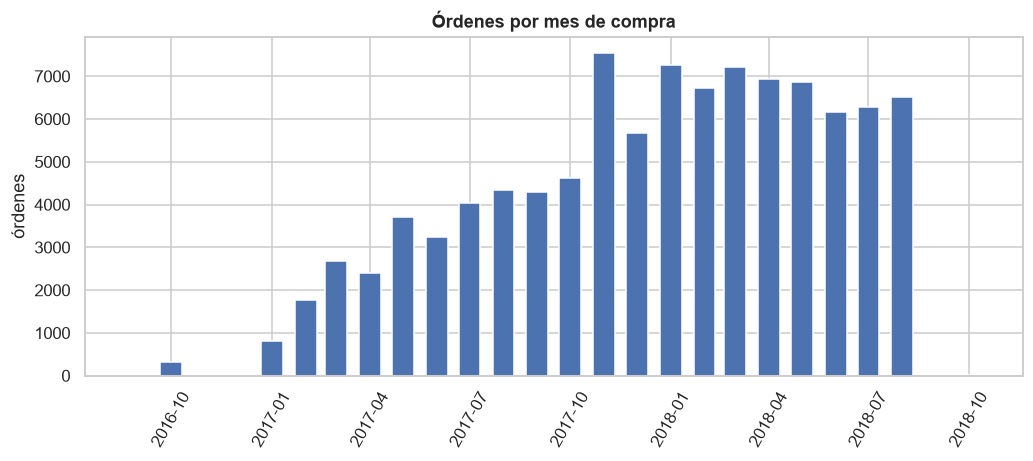

,mes,order_status,ordenes
126,2018-07-01,shipped,60
127,2018-07-01,unavailable,18
128,2018-08-01,canceled,84
129,2018-08-01,delivered,6351
130,2018-08-01,invoiced,23
131,2018-08-01,shipped,47
132,2018-08-01,unavailable,7
133,2018-09-01,canceled,15
134,2018-09-01,shipped,1
135,2018-10-01,canceled,4


,mes,ordenes,entregadas,canceladas
0,2016-09-01,4,1.0,2.0
1,2016-10-01,324,265.0,24.0
2,2016-12-01,1,1.0,0.0
3,2017-01-01,800,750.0,3.0
4,2017-02-01,1780,1653.0,17.0
5,2017-03-01,2682,2546.0,33.0
6,2017-04-01,2404,2303.0,18.0
7,2017-05-01,3700,3546.0,29.0
8,2017-06-01,3245,3135.0,16.0
9,2017-07-01,4026,3872.0,28.0


In [8]:
cobertura = consulta(con, "00_datos/cobertura_mensual.sql")
fig, ax = plt.subplots()
ax.bar(cobertura["mes"], cobertura["ordenes"], width=20)
ax.set_title("Órdenes por mes de compra")
ax.set_ylabel("órdenes")
ax.tick_params(axis="x", labelrotation=60)
guardar(fig, "cobertura_mensual", "00_datos")
display(fig)
plt.close(fig)
estados_mensuales = consulta(con, "00_datos/ordenes_estados_mensual.sql")
display(estados_mensuales.tail(10))
cobertura

In [9]:
print("Período útil [inicio, fin):", config.FECHA_INICIO_UTIL, "→", config.FECHA_FIN_UTIL)

Período útil [inicio, fin): 2017-01-05 → 2018-08-22


**Decisión acordada:** usar `[2017-01-05, 2018-08-22)`, es decir, hasta el 21 de agosto inclusive. En 2016 hubo 4 órdenes en septiembre, 324 en octubre, ninguna en noviembre y 1 en diciembre; el 1–4 de enero de 2017 también tuvo cero órdenes y el día 5 tuvo 32. En 2017-01 se registraron 800 órdenes, primer mes con actividad sostenida. El extremo final cae de 243 órdenes el 21 de agosto a 187 el 22, 144 el 23 y 14 el 29; luego hay 4 el 30 y 1 el 31. Septiembre totaliza 16 y octubre 4. Se excluye desde el 22 de agosto para evitar modelar el colapso de cobertura como si fuera una caída genuina de demanda. Se eligió el 21 como último día previo al descenso; esto debe explicarse como limitación de cobertura, no como una fecha de corte operacional.

## 5. EDA orientado a los módulos

El EDA incluye conteos diarios y semanales, duración de entrega y retraso frente a la fecha estimada, distribución estatal de clientes y vendedores, y frecuencia de compra por persona. Para la serie de B se definió demanda como **todos los pedidos por fecha de compra, sin excluir estados**: se quiere contar lo que recibe Olist; cancelación e indisponibilidad son desenlaces posteriores. La base contiene 99.441 pedidos: 96.478 `delivered`, 625 `canceled`, 609 `unavailable` y 1.729 en otros estados.

### 5.1 Órdenes por día y cierre de la extracción

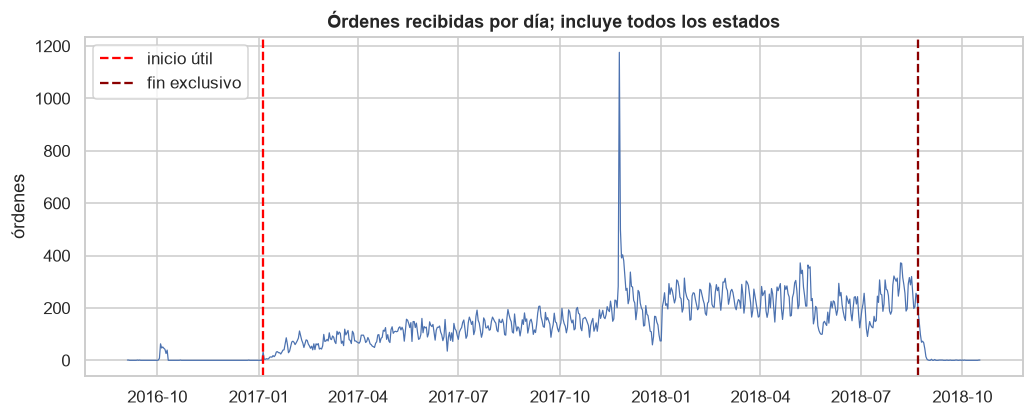

,order_status,ordenes,primera_fecha_compra,ultima_fecha_compra,dias_con_ordenes
0,delivered,96478,2016-09-15,2018-08-29,612
1,shipped,1107,2016-09-04,2018-09-03,466
2,canceled,625,2016-09-05,2018-10-17,344
3,unavailable,609,2016-10-05,2018-08-21,309
4,invoiced,314,2016-10-04,2018-08-14,212
5,processing,301,2016-10-05,2018-07-23,206
6,created,5,2017-11-06,2018-02-09,4
7,approved,2,2017-02-06,2017-04-25,2


,fecha,order_status,ordenes
0,2018-08-15,canceled,5
1,2018-08-15,delivered,282
2,2018-08-15,shipped,1
3,2018-08-16,canceled,4
4,2018-08-16,delivered,316
5,2018-08-17,canceled,3
6,2018-08-17,delivered,249
7,2018-08-17,shipped,5
8,2018-08-18,canceled,2
9,2018-08-18,delivered,193


In [10]:
diaria = consulta(con, "00_datos/ordenes_diarias_completas.sql")
fig, ax = plt.subplots()
ax.plot(diaria["fecha"], diaria["ordenes"], lw=0.8)
ax.axvline(pd.Timestamp(config.FECHA_INICIO_UTIL), color="red", ls="--", label="inicio útil")
ax.axvline(pd.Timestamp(config.FECHA_FIN_UTIL), color="darkred", ls="--", label="fin exclusivo")
ax.set_title("Órdenes recibidas por día; incluye todos los estados")
ax.set_ylabel("órdenes")
ax.legend()
guardar(fig, "ordenes_diarias", "00_datos")
display(fig)
plt.close(fig)

resumen_estados = consulta(con, "00_datos/ordenes_estado_resumen.sql")
display(resumen_estados)
inicio_cola = (pd.Timestamp(config.FECHA_FIN_UTIL) - pd.Timedelta(days=7)).date().isoformat()
fin_observado = pd.Timestamp(diaria["fecha"].max())
fin_cola = (fin_observado + pd.Timedelta(days=1)).date().isoformat()
cobertura_cola = consulta(
    con, "00_datos/cobertura_diaria_estados.sql", [inicio_cola, fin_cola]
)
display(cobertura_cola)

**Lectura.** La demanda crece durante 2017 y se estabiliza en 2018. El pico aislado es Black Friday
(24-nov-2017). La cola final confirma el corte de extracción: desde el 22 de agosto las órdenes caen día a día
(185 entregadas el 22, 96 el 24, 39 el 28 y 11 el 29), y desde el 30 solo aparecen canceladas o en
tránsito. Casi todo lo que sobrevive en esos días figura como entregado, lo que sugiere que el dataset
conservó sobre todo las órdenes ya cerradas. Es un corte de la extracción, no una caída de la demanda;
por eso el período útil termina el 21 de agosto.

### 5.2 Órdenes por semana

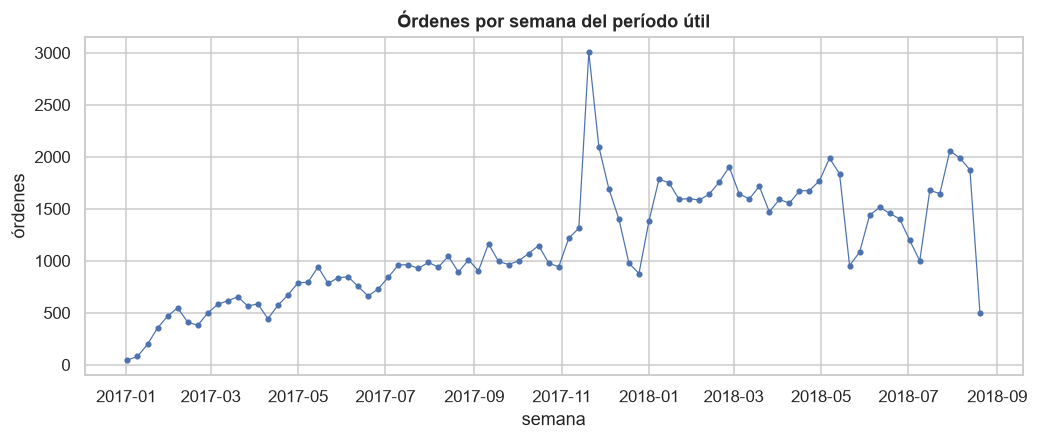

trimestre
2017Q1     415.0
2017Q2     723.0
2017Q3     968.0
2017Q4    1363.0
2018Q1    1647.0
2018Q2    1533.0
2018Q3    1493.0
Freq: Q-DEC, Name: media_semanal, dtype: float64

In [11]:
semanal = consulta(
    con,
    "00_datos/ordenes_semanales.sql",
    [config.FECHA_INICIO_UTIL, config.FECHA_FIN_UTIL,
     config.FECHA_INICIO_UTIL, config.FECHA_FIN_UTIL],
)
fig, ax = plt.subplots()
ax.plot(semanal["semana"], semanal["ordenes"], marker=".", lw=0.8)
ax.set(title="Órdenes por semana del período útil", ylabel="órdenes", xlabel="semana")
guardar(fig, "ordenes_semanales", "00_datos")
display(fig)
plt.close(fig)
semanal.assign(trimestre=pd.to_datetime(semanal["semana"]).dt.to_period("Q")) \
    .groupby("trimestre")["ordenes"].mean().round(0).rename("media_semanal")

**Lectura.** La media semanal pasa de 415 órdenes en el primer trimestre de 2017 a 1.363 en el cuarto, y
llega a 1.647 en el primer trimestre de 2018. Después baja levemente (1.533 y 1.493 en los trimestres 2 y
3 de 2018). La semana máxima es la de Black Friday (3.008 órdenes, desde el 2017-11-20). La primera y la
última semana están incompletas (46 y 499 órdenes), porque el período útil empieza un jueves y termina un
martes. No son caídas reales de demanda. Para el Módulo B esto implica una tendencia que no es lineal:
crece en 2017 y se aplana en 2018.

### 5.3 Tiempos de entrega y retraso

,entregas_comparables,entregas_tardias,porcentaje_tardias,mediana_dias_entrega,p90_dias_entrega,mediana_dias_vs_estimado,p90_dias_vs_estimado,minimo_dias_vs_estimado,maximo_dias_vs_estimado
0,96470,6534,6.773,10,23,-12,-2,-147,188


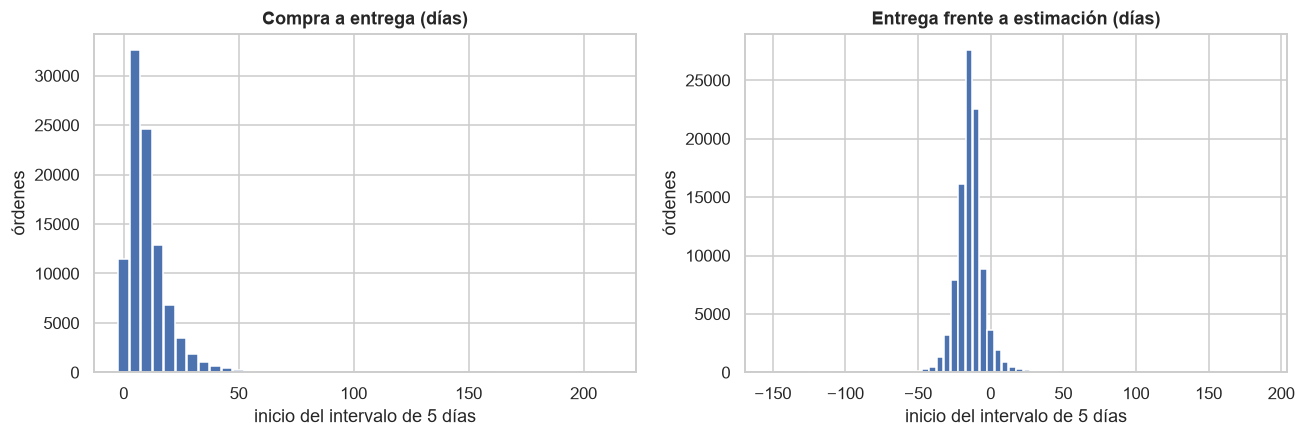

In [12]:
entregas = consulta(con, "00_datos/tiempos_entrega.sql")
resumen_entregas = consulta(con, "00_datos/entregas_resumen.sql")
display(resumen_entregas)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, medida, titulo in zip(
    axes,
    ["tiempo_entrega", "retraso_vs_estimado"],
    ["Compra a entrega (días)", "Entrega frente a estimación (días)"],
):
    datos = entregas[entregas["medida"] == medida]
    ax.bar(datos["inicio_intervalo_dias"], datos["ordenes"], width=4.5)
    ax.set(title=titulo, xlabel="inicio del intervalo de 5 días", ylabel="órdenes")
guardar(fig, "distribucion_entregas", "00_datos")
display(fig)
plt.close(fig)

**Lectura.** Hay 96.470 entregas con fechas comparables. La mediana de compra a entrega es de 10 días, el
percentil 90 es de 23, y el 4,9 % tarda 30 días o más. Frente a la fecha estimada, la mediana llega 12 días
antes y el percentil 90, 2 días antes: Olist promete fechas holgadas. Solo el 6,77 % llega tarde. Los
extremos (de −147 a +188 días) se conservan, pero no deben dominar los promedios; por eso se reportan
medianas y percentiles.

### 5.4 Distribución geográfica de clientes y vendedores

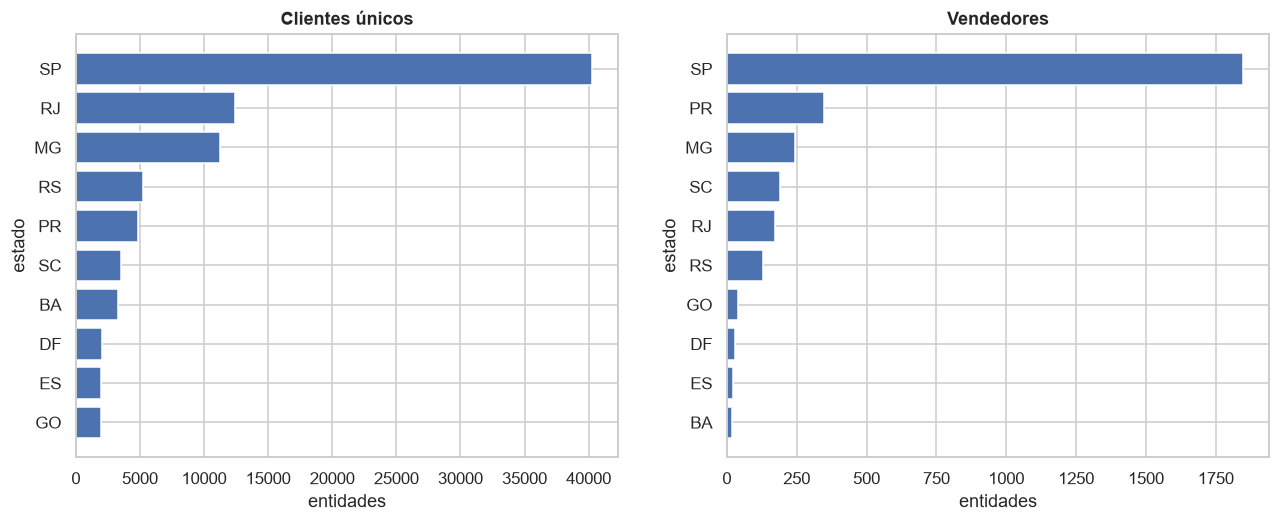

Principales estados por clientes y vendedores:


,entidad,estado,entidades,ordenes,items
0,clientes,SP,40302,41746,<NA>
1,clientes,RJ,12384,12852,<NA>
2,clientes,MG,11259,11635,<NA>
3,clientes,RS,5277,5466,<NA>
4,clientes,PR,4882,5045,<NA>
5,clientes,SC,3534,3637,<NA>
6,clientes,BA,3277,3380,<NA>
7,clientes,DF,2075,2140,<NA>
27,vendedores,SP,1849,70188,80342
28,vendedores,PR,349,7673,8671


In [13]:
geografia = consulta(con, "00_datos/geografia.sql")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, entidad, titulo in zip(axes, ["clientes", "vendedores"], ["Clientes únicos", "Vendedores"]):
    datos = geografia[geografia["entidad"] == entidad].nlargest(10, "entidades").sort_values("entidades")
    ax.barh(datos["estado"], datos["entidades"])
    ax.set(title=titulo, xlabel="entidades", ylabel="estado")
guardar(fig, "geografia_estados", "00_datos")
display(fig)
plt.close(fig)
print("Principales estados por clientes y vendedores:")
display(geografia.sort_values(["entidad", "entidades"], ascending=[True, False]).groupby("entidad").head(8))

**Lectura.** Hay clientes en 27 estados, pero São Paulo concentra el 41,9 % de las personas, y SP, RJ y MG
suman el 66,5 %. La oferta está aún más concentrada: el 59,7 % de los vendedores está en SP, que despacha
70.188 órdenes, y SP, PR y MG reúnen el 78,9 % de los vendedores. La serie nacional del Módulo B está
dominada por SP, y el plan de capacidad del Módulo D se distribuye según el estado de origen de los
vendedores.

### 5.5 Comportamiento de compra por cliente

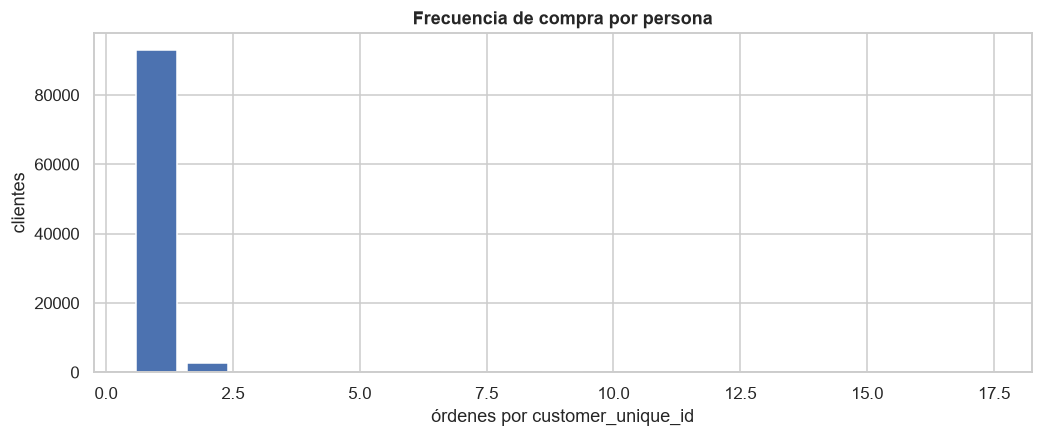

,ordenes,clientes,porcentaje_clientes
0,1,93099,96.881
1,2,2745,2.857
2,3,203,0.211
3,4,30,0.031
4,5,8,0.008
5,6,6,0.006
6,7,3,0.003
7,9,1,0.001
8,17,1,0.001


In [14]:
fig, ax = plt.subplots()
ax.bar(frecuencia_clientes["ordenes"], frecuencia_clientes["clientes"])
ax.set(title="Frecuencia de compra por persona", xlabel="órdenes por customer_unique_id", ylabel="clientes")
guardar(fig, "frecuencia_clientes", "00_datos")
display(fig)
plt.close(fig)
frecuencia_clientes

**Lectura.** El 96,9 % de las personas (93.099 de 96.096) compró una sola vez; solo 2.997 repitieron.
La demanda diaria depende de la llegada de clientes nuevos y no de la recompra, así que el Módulo B modela
el total de órdenes y no intenta explicarlo por clientes recurrentes.

## Conclusiones del Módulo 0: decisiones para los módulos siguientes

- Hay 96.470 órdenes entregadas con fecha real y estimada comparables; 6.534 llegaron después del día estimado (6,773 %). La mediana compra-entrega es 10 días y el percentil 90 es 23 días. El retraso mediano es -12 días (antes de la estimación), pero el máximo es 188 días; conservar los extremos para investigarlos, no asumir que son errores sin evidencia.
- Los faltantes de comentarios de reseña son altos y esperables en texto opcional. Productos tienen 610 filas sin categoría (1,851 %) y 13 productos repartidos en 2 categorías sin traducción (0,039 % de productos; 2 de 73 categorías). Hay 775 órdenes sin ítems (0,779 %), 1 sin pagos y 380 discrepancias de pago superiores a 0,01 entre 98.665 órdenes comparables (0,385 %). No borrar automáticamente: reportar y excluir solo según la pregunta.
- Faltan 157 prefijos postales de clientes (1,047 % de los prefijos observados; 278 filas de clientes) y 7 de vendedores (0,312 % de sus prefijos; 7 filas). Además, `geolocation` repite muchos prefijos. Para cualquier análisis de distancia o variable regional, resumir geolocalización por prefijo y marcar las ubicaciones faltantes.
- La mediana de compras es una orden por persona: 93.099 de 96.096 personas (96,881 %) compraron una vez; solo 2.997 compraron más de una. La frecuencia de compra repetida describe a una minoría y el identificador de persona debe ser `customer_unique_id`.
- La concentración geográfica es alta: São Paulo reúne 40.302 clientes únicos y 41.746 órdenes; hay 1.849 vendedores de SP con 70.188 órdenes y 80.342 ítems. El EDA por estado no corrige el sesgo de cobertura ni convierte automáticamente pedidos en despachos.
- En `calidad_fechas.sql` hay 165 registros con fecha de entrega al transportador anterior a la compra y 23 entregas al cliente anteriores a la fecha del transportador; 8 órdenes `delivered` no tienen fecha real de entrega. Cualquier análisis del tiempo de entrega debe utilizar solo fechas observadas coherentes.
- La serie de B incluye todos los estados y se mide por fecha de compra. Describe pedidos recibidos, no entregas ni carga logística neta. El período útil acordado está en `config.py`; no elimina los problemas de calidad y cobertura documentados arriba.

In [15]:
con.close()